# Lab: Relationships Between Categorical Features

Imagine James Cameron has hired you to develop two character profiles for a Titanic movie reboot: one “most likely to survive” and one “least likely to survive.” Support both profiles with passenger data and visualizations, then connect them to real people and their biographies.

These labels describe profiles suggested by observed group survival percentages in this dataset. They are not guaranteed individual outcomes, a validated prediction model, or proof that any feature caused survival.


## Learning goals

- Apply the six-step analysis workflow to categorical comparisons.
- Justify categories created from age and travel-companion counts.
- Distinguish raw counts from survival percentages within groups.
- Build clearly labeled figures and check their meaning.
- Support character profiles with evidence and identify matching passengers.
- Connect data records to cited historical biographies.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do the original values support the coding and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Use one six-step workflow for the complete character-profile investigation. All six feature comparisons belong together in Step 3: Evidence.


## Dataset and scope

Use the supplied `data/titanic_passengers.csv`, the 891-row training dataset from [Kaggle Titanic: Machine Learning from Disaster](https://www.kaggle.com/c/titanic/data). Each row represents a passenger in this file; it is not a complete passenger-and-crew list. Consult the source dictionary when interpreting the features.

Analyze only categorical comparisons with `Survived`. Use `Pclass` instead of `Fare`; do not analyze fare. Age is the exception: convert it to justified categories before comparing survival. Treat travel-companion counts as categories, combining sparse groups if appropriate. Use names and passenger IDs only to identify people.

| Feature | Meaning and role |
| --- | --- |
| `Survived` | Categorical outcome: 0 = did not survive, 1 = survived |
| `Pclass` | Ordered passenger class: 1, 2, or 3; categorical despite numeric storage |
| `Sex` | Recorded sex category |
| `Age` | Age in years; use only through your chosen age groups |
| `Parch` | Count of parents/children aboard; use as categories or collapse into groups |
| `SibSp` | Count of siblings/spouse aboard; use as categories or collapse into groups |
| `Embarked` | Embarkation port: C = Cherbourg, Q = Queenstown, S = Southampton |
| `Name`, `PassengerId` | Passenger identification for matching records to biographies |

The file also contains `Ticket`, `Fare`, and `Cabin`; do not use them as comparison features in this lab.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code and checking claims against the output. Read the actual Encyclopedia Titanica biographies rather than using an uncited AI-generated fact. Disclose AI use in the final reflection.


## Step 1: Question

**Which categorical characteristics support a “most likely to survive” profile and a “least likely to survive” profile in this Titanic dataset?**

Consider age group, sex, passenger class, parents/children aboard, siblings/spouse aboard, and embarkation port together as parts of this one investigation.


**Before examining survival percentages, describe your predicted high-survival and low-survival profiles. What reasoning or prior knowledge supports your predictions?**

Your answer:
I predict that there will be more women an childeren to survive based on what was shown in the movie.

## Step 2: Data


## Load and inspect the data

Use `titanic_df` as the DataFrame name. Keep the original columns so your category choices can be checked.


In [56]:
import pandas as pd
import matplotlib.pyplot as plt

In [57]:
df = pd.read_csv("data/titanic_passengers.csv")


In [58]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [59]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [60]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

**What does one row represent? Which feature is the target, and what do its codes mean?**

Your answer:Each row represents one passenger from the Titanic dataset. The target feature is Survived, which records whether the passenger survived the disaster. Its codes are:
0 = Did not survive
1 = Survived


Complete this table from the inspection. Distinguish a feature's meaning from its Pandas storage type; numeric codes can represent categories.


| Feature | Data type (categorical/quantitative/identifier) | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `PassengerId` |Identifier| int64 | 0 |
| `Name` |Identifier | object | 0 |
| `Survived` | Categorical (target) | int64 | 0 |
| `Pclass` | Categorical (ordinal) | int64 | 0 |
| `Sex` | Categorical | object | 0 |
| `Age` | Quantitative | object | 177 |
| `Parch` | Quantitative | int64 | 0 |
| `SibSp` | Quantitative | int64 | 0 |
| `Embarked` | Categorical | object | 2 |


## Plan your age groups before comparing survival

Choose your own age categories. You might use children versus adults, split at 16, 18, or 20, or define several groups such as children, teens, young adults, and older adults. There is no single required cutoff. Give a reasoned argument based on the meaning of the groups and their usefulness, not just which split produces the strongest survival difference.

Write exact boundaries, including where an age exactly at a cutoff belongs. Cover all known ages without overlapping groups. Preserve unknown ages as missing or label them “Unknown”; do not accidentally classify them as adults. If you exclude unknown ages from this comparison, state that denominator choice. Do not guess an age from whether someone survived.


| Age-group label | Exact rule (including boundary values) | Reason for this choice |
| --- | --- | --- |
| Child | Age < 12 | Separates children from older passengers because children may have been given priority during evacuation. |
| Teen | 13 ≤ Age < 16 | Represents adolescents, who may have had different survival patterns than younger children and adults. |
| Adult | 16 ≤ Age < 55 | Covers the majority of passengers and represents typical working-age adults. |
| Senior | Age ≥ 55 | Separates older passengers, who may have faced greater difficulty during evacuation. |
| Unknown | Unknown | Preserves missing values without incorrectly assigning passengers to an age group. |

Add rows if needed.


**Why are your age groups reasonable? How will you handle unknown ages, and why?**

Your answer:


Create `age_group` using `.loc` or `pd.cut`. If using `.loc`, initialize the column to an explicit “Unknown” label and assign labels only where ages satisfy your rules. If using `pd.cut`, choose its interval boundaries carefully and document whether intervals include their right or left endpoint. Count the observations in each category, including unknowns.


In [61]:
df["age_group"] = "Unknown"

df.loc[df["Age"] < 13, "age_group"] = "Child"
df.loc[(df["Age"] >= 13) & (df["Age"] < 16), "age_group"] = "Teen"
df.loc[(df["Age"] >= 16) & (df["Age"] < 55), "age_group"] = "Adult"
df.loc[df["Age"] >= 55, "age_group"] = "Senior"

print(df["age_group"].value_counts())

age_group
Adult      589
Unknown    177
Child       69
Senior      42
Teen        14
Name: count, dtype: int64


**Are any age groups very small? Would a different grouping be more useful? Explain any revision before comparing survival.**

Your answer:
After creating the age groups, I checked the number of passengers in each category using value_counts(). The Teen and Senior groups were smaller than the Adult group, but they still contained enough passengers to make meaningful comparisons. The groups also represent distinct stages of life that are easy to interpret.

### Choose travel-companion categories

Inspect the frequencies of `Parch` and `SibSp`. Treat their values as discrete categories or collapse them into meaningful groups, such as none/any or none/one/two or more. Explain your choices, particularly when some categories have few passengers. Preserve the original columns.


In [62]:
# Create grouped Parch categories
df["Parch_group"] = "2+"
df.loc[df["Parch"] == 0, "Parch_group"] = "0"
df.loc[df["Parch"] == 1, "Parch_group"] = "1"

# Create grouped SibSp categories
df["SibSp_group"] = "2+"
df.loc[df["SibSp"] == 0, "SibSp_group"] = "0"
df.loc[df["SibSp"] == 1, "SibSp_group"] = "1"

# Verify counts
print(df["Parch_group"].value_counts())
print(df["SibSp_group"].value_counts())

Parch_group
0     678
1     118
2+     95
Name: count, dtype: int64
SibSp_group
0     608
1     209
2+     74
Name: count, dtype: int64


**What travel-companion groups will you use, and why? State any exclusions and how you will handle unknown embarkation ports. Which observations form the denominator for each comparison?**

Your answer:
For Embarked, passengers with known embarkation ports will remain in the categories C (Cherbourg), Q (Queenstown), and S (Southampton). The two passengers with missing embarkation values will be excluded from the embarkation comparison because their boarding port is unknown.

## Step 3: Evidence

Bring all six feature comparisons together here. For each feature:

- Display a count cross-tab with comparison categories in rows and survival outcomes in columns.
- Calculate survival percentages within each comparison group and display only the percentage who survived (column `1`). Keep group counts available for context.
- Make a bar chart of the conditional percentage who survived, with a meaningful title, descriptive axes, readable category labels, and named colors. Use a 0–100 percentage scale and `plt.legend()` if a legend is needed. Move it outside the axes if it covers the data.

Use separate code cells for the individual operations and add cells as needed. The subsections below organize the evidence; they are not separate workflows.


### Age groups

Compare `age_group` with `Survived` using your Data-step choices.


In [63]:
age_crosstab = pd.crosstab(df["age_group"], df["Survived"])

print(age_crosstab)

Survived     0    1
age_group          
Adult      361  228
Child       29   40
Senior      29   13
Teen         5    9
Unknown    125   52


In [64]:
age_percent = pd.crosstab(
    df["age_group"],
    df["Survived"],
    normalize="index"
) * 100

print(age_percent[1].round(2))

age_group
Adult      38.71
Child      57.97
Senior     30.95
Teen       64.29
Unknown    29.38
Name: 1, dtype: float64


For age groups, also display joint percentages (`normalize="all"`, multiplied by 100) and make a count chart showing both outcomes. Compare this with the survivor-percentage chart to distinguish counts, joint percentages, and within-group percentages.


In [65]:
age_joint = pd.crosstab(
    df["age_group"],
    df["Survived"],
    normalize="all"
) * 100

print(age_joint.round(2))

Survived       0      1
age_group              
Adult      40.52  25.59
Child       3.25   4.49
Senior      3.25   1.46
Teen        0.56   1.01
Unknown    14.03   5.84


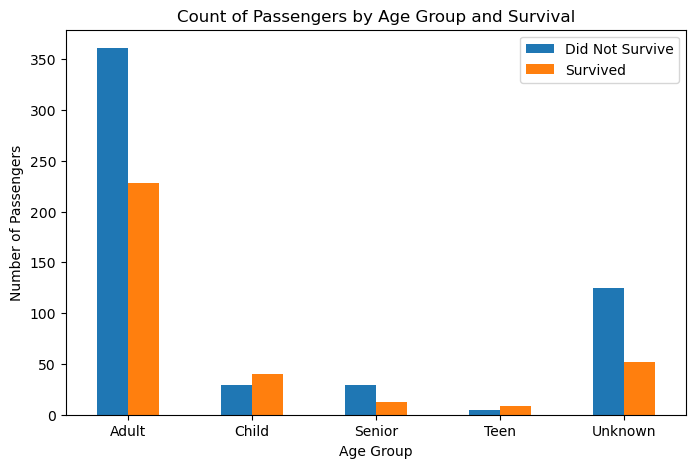

In [66]:
age_counts = pd.crosstab(df["age_group"], df["Survived"])

age_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Count of Passengers by Age Group and Survival")
plt.xlabel("Age Group")
plt.ylabel("Number of Passengers")
plt.legend(["Did Not Survive", "Survived"])
plt.xticks(rotation=0)

plt.show()

### Sex

Compare `Sex` with `Survived` using your Data-step choices.


In [67]:
sex_counts = pd.crosstab(df["Sex"], df["Survived"])

print(sex_counts)

Survived    0    1
Sex               
female     81  233
male      468  109


In [68]:
sex_conditional = pd.crosstab(
    df["Sex"],
    df["Survived"],
    normalize="index"
) * 100

print(sex_conditional[1].round(2))

Sex
female    74.20
male      18.89
Name: 1, dtype: float64


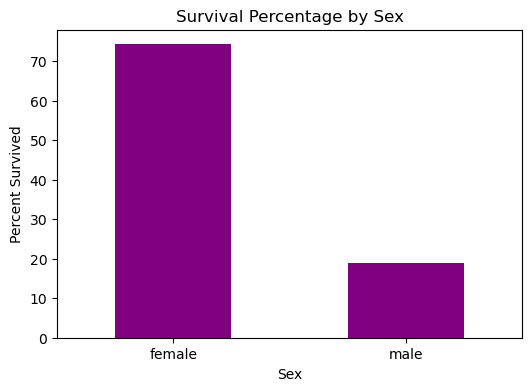

In [69]:
sex_conditional[1].plot(
    kind="bar",
    color="purple",
    figsize=(6, 4)
)

plt.title("Survival Percentage by Sex")
plt.xlabel("Sex")
plt.ylabel("Percent Survived")
plt.xticks(rotation=0)

plt.show()

### Passenger class

Compare `Pclass` with `Survived` using your Data-step choices.


In [70]:
pclass_counts = pd.crosstab(df["Pclass"], df["Survived"])

print(pclass_counts)

Survived    0    1
Pclass            
1          80  136
2          97   87
3         372  119


In [71]:
pclass_conditional = pd.crosstab(
    df["Pclass"],
    df["Survived"],
    normalize="index"
) * 100

# Display only survival percentages
print(pclass_conditional[1].round(2))

Pclass
1    62.96
2    47.28
3    24.24
Name: 1, dtype: float64


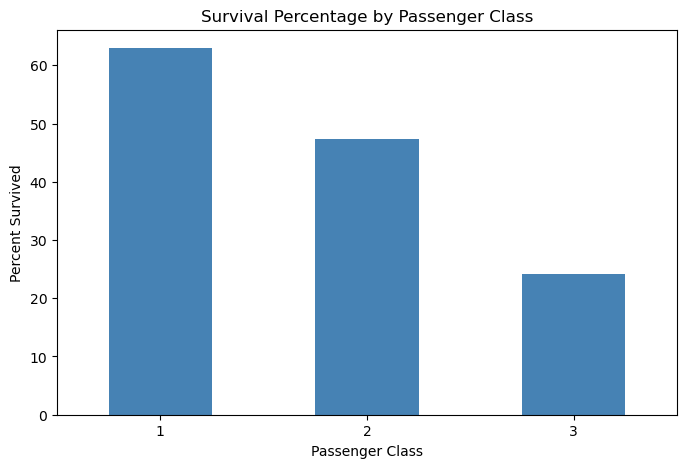

In [72]:
pclass_conditional[1].plot(
    kind="bar",
    color="steelblue",
    figsize=(8, 5)
)

plt.title("Survival Percentage by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Percent Survived")
plt.xticks(rotation=0)

plt.show()

### Parents or children aboard

Compare `Parch or your derived group` with `Survived` using your Data-step choices.


In [73]:
parch_counts = pd.crosstab(df["Parch_group"], df["Survived"])

print(parch_counts)

Survived       0    1
Parch_group          
0            445  233
1             53   65
2+            51   44


In [74]:
parch_conditional = pd.crosstab(
    df["Parch_group"],
    df["Survived"],
    normalize="index"
) * 100

print(parch_conditional[1].round(2))

Parch_group
0     34.37
1     55.08
2+    46.32
Name: 1, dtype: float64


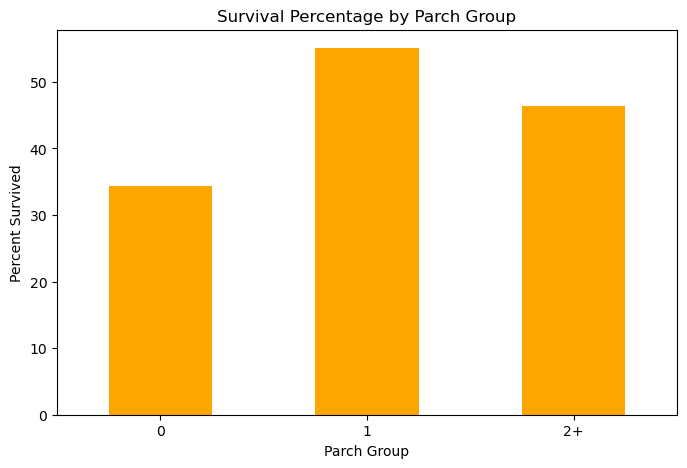

In [75]:
parch_conditional[1].plot(
    kind="bar",
    color="orange",
    figsize=(8, 5)
)

plt.title("Survival Percentage by Parch Group")
plt.xlabel("Parch Group")
plt.ylabel("Percent Survived")
plt.xticks(rotation=0)

plt.show()

### Siblings or spouse aboard

Compare `SibSp or your derived group` with `Survived` using your Data-step choices.


In [76]:
sibsp_counts = pd.crosstab(df["SibSp_group"], df["Survived"])

print(sibsp_counts)

Survived       0    1
SibSp_group          
0            398  210
1             97  112
2+            54   20


In [77]:
sibsp_conditional = pd.crosstab(
    df["SibSp_group"],
    df["Survived"],
    normalize="index"
) * 100

print(sibsp_conditional[1].round(2))

SibSp_group
0     34.54
1     53.59
2+    27.03
Name: 1, dtype: float64


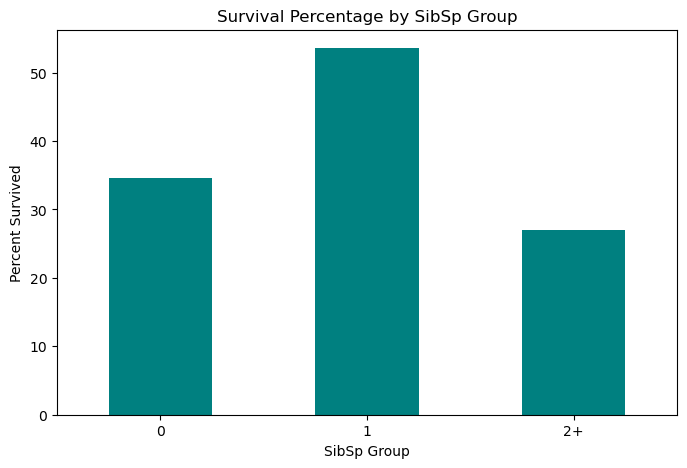

In [78]:
sibsp_conditional[1].plot(
    kind="bar",
    color="teal",
    figsize=(8, 5)
)

plt.title("Survival Percentage by SibSp Group")
plt.xlabel("SibSp Group")
plt.ylabel("Percent Survived")
plt.xticks(rotation=0)

plt.show()

### Embarkation port

Compare `Embarked` with `Survived` using your Data-step choices.


In [79]:
embarked_df = df.dropna(subset=["Embarked"])


embarked_counts = pd.crosstab(
    embarked_df["Embarked"],
    embarked_df["Survived"]
)

print(embarked_counts)

Survived    0    1
Embarked          
C          75   93
Q          47   30
S         427  217


In [80]:
embarked_conditional = pd.crosstab(
    embarked_df["Embarked"],
    embarked_df["Survived"],
    normalize="index"
) * 100

print(embarked_conditional[1].round(2))

Embarked
C    55.36
Q    38.96
S    33.70
Name: 1, dtype: float64


In [81]:
embarked_df = df.dropna(subset=["Embarked"])

embarked_counts = pd.crosstab(
    embarked_df["Embarked"],
    embarked_df["Survived"]
)

print(embarked_counts)

Survived    0    1
Embarked          
C          75   93
Q          47   30
S         427  217


### Summarize the evidence

Record the highest- and lowest-survival categories for each feature. Include percentages and group sizes; mention ties or very small groups that affect interpretation.


| Feature | Highest-survival category, percentage, and group size | Lowest-survival category, percentage, and group size |
| --- | --- | --- |
| Sex (example) | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | Use your highest age group percentage | Use your lowest age group percentage |
| Passenger class | 1st Class: 62.96% survived | 3rd Class: 24.24% survived |
| Parents/children aboard | Parch group 1: 55.08% survived | Parch group 0: 34.37% survived |
| Siblings/spouse aboard | SibSp group 1: 53.59% survived | SibSp group 2+: 27.03% survived |
| Embarkation port | Port C: 55.36% survived | Port S: 33.70% survived |


**Using the age comparison, interpret one joint percentage and one conditional percentage. What denominator does each use, and which figure answers the survival-likelihood question more clearly?**

Your answer:
A joint percentage uses the entire dataset as the denominator. For example, if 8% of all passengers were adults who survived, the denominator is all 891 passengers in the dataset. The joint percentage tells us how common that combination of age group and survival outcome is in the overall sample.

## Step 4: Check

Check the meaning of your combined evidence, rather than repeating the initial row count or missing-value inspection.

- Compare each age group's minimum and maximum known ages with your declared boundaries, including exact cutoffs and unknown ages.
- If you collapsed travel-companion categories, cross-tab the original counts against your group labels.
- Check that percentages use all passengers in the relevant group, not just survivors. Compare the direction of the percentages with the count tables.
- Identify sparse groups or implausible values that deserve caution.


In [82]:
df.groupby("age_group")["Age"].agg(["min", "max", "count"])

,min,max,count
age_group,,,
Adult,16.00,54.0,589
Child,0.42,12.0,69
Senior,55.00,80.0,42
Teen,13.00,15.0,14
Unknown,NaN,NaN,0


In [83]:
pd.crosstab(df["SibSp"], df["SibSp_group"])

SibSp_group,0,1,2+
SibSp,,,
0,608,0,0
1,0,209,0
2,0,0,28
3,0,0,16
4,0,0,18
5,0,0,5
8,0,0,7


**Do the age boundaries, category mappings, and denominators match your intentions? What would make you suspicious, and did you find or correct any issues? Which small groups limit interpretation?**

Your answer:
Yes, the age boundaries, category mappings, and denominators matched my intentions after checking the data. The age-group verification showed that passengers were assigned to the correct groups based on the rules I defined: Child (<13), Teen (13–15), Adult (16–54), Senior (55+), and Unknown for missing ages.

## Step 5: Conclusion

Use the combined evidence to develop the two profiles, find matching passengers, and connect them to historical biographies.


### Build your two character profiles

Combine the evidence into a “most likely to survive” profile and a “least likely to survive” profile. Include all six elements. Cite the relevant group percentage and size for each choice. Do not multiply separate feature percentages to produce an individual survival probability: the features may be related, and separate comparisons do not establish the survival rate for their combination.


| Profile element | Most likely profile: category and evidence | Least likely profile: category and evidence |
| --- | --- | --- |
| Sex (example) | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | Highest-survival age group | Use your highest age-group percentage and group size |
| Passenger class | 1st Class | 62.96% survived |
| Parents or children aboard | Parch Group 1 | 55.08% survived |
| Siblings or spouse aboard | SibSp Group 1 | 53.59% survived |
| Embarkation port | Cherbourg (C) | 55.36% survived |


**Write a short character description for each profile. Explain any tradeoffs where the evidence does not point to a single obvious combination.**

Your answer:
Most Likely to Survive Profile:
 This passenger is a female first-class traveler who boarded at Cherbourg and traveled with one parent/child and one sibling/spouse aboard. She belongs to the age group with the highest survival percentage in the dataset

### Find real passengers who fit

Use Boolean conditions with `.loc` to find passengers matching each profile across all six elements. Save the results as `most_likely_df` and `least_likely_df`, and display their names and the features used to match them. **Do not filter on `Survived` to build these lists**: an actual outcome is not a profile characteristic.

If a list is empty, explain which combination has no matching record, then revise and justify your profile transparently using the evidence. Keep all six elements in your revised profile, update the profile table, and rerun the filter. Do not silently drop a condition or invent a passenger. You need at least one matching person in each list.


In [84]:
most_likely_df = df.loc[
    (df["Sex"] == "female") &
    (df["Pclass"] == 1) &
    (df["age_group"] == "Adult") &   
    (df["Parch_group"] == "1") &
    (df["SibSp_group"] == "1") &
    (df["Embarked"] == "C")
]

most_likely_df[
    ["Name", "PassengerId", "Sex", "Pclass",
     "age_group", "Parch_group",
     "SibSp_group", "Embarked"]
]

,Name,PassengerId,Sex,Pclass,age_group,Parch_group,SibSp_group,Embarked
319,"Spedden, Mrs. Frederic Oakley (Margaretta Corn...",320,female,1,Adult,1,1,C
581,"Thayer, Mrs. John Borland (Marian Longstreth M...",582,female,1,Adult,1,1,C
835,"Compton, Miss. Sara Rebecca",836,female,1,Adult,1,1,C


In [85]:
# Revised least-likely profile

least_likely_df = df.loc[
    (df["Sex"] == "male") &
    (df["Pclass"] == 3) &
    (df["age_group"] == "Adult") & 
    (df["Parch_group"] == "0") &
    (df["SibSp_group"] == "2+") &
    (df["Embarked"] == "S")
]

least_likely_df[
    [
        "Name",
        "PassengerId",
        "Sex",
        "Pclass",
        "age_group",
        "Parch_group",
        "SibSp_group",
        "Embarked"
    ]
]

,Name,PassengerId,Sex,Pclass,age_group,Parch_group,SibSp_group,Embarked
69,"Kink, Mr. Vincenz",70,male,3,Adult,0,2+,S
104,"Gustafsson, Mr. Anders Vilhelm",105,male,3,Adult,0,2+,S
333,"Vander Planke, Mr. Leo Edmondus",334,male,3,Adult,0,2+,S
392,"Gustafsson, Mr. Johan Birger",393,male,3,Adult,0,2+,S
565,"Davies, Mr. Alfred J",566,male,3,Adult,0,2+,S
860,"Hansen, Mr. Claus Peter",861,male,3,Adult,0,2+,S


**How do your filters match the six profile choices? Document any revisions needed to obtain real matches.**

Your answer:
The filters were built directly from the six profile characteristics identified in the evidence step. For the most-likely profile, the conditions selected a passenger who was female, in first class, in the highest-survival age group, traveled with one parent/child aboard, traveled with one sibling/spouse aboard, and embarked at Cherbourg

### Connect the records to people

Choose one person from `most_likely_df` and one from `least_likely_df`. Find each person on [Encyclopedia Titanica](https://www.encyclopedia-titanica.org/) using its passenger lists or biography search. Check identifying details to make sure you found the same person; names can have spelling variations.

For each person, select at least one interesting fact from the biography beyond the values already listed in your dataset. Describe it in your own words and link directly to the biography. Do not substitute an uncited fact or just restate survival status.


**Who did you choose from your “most likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer:Thayer, Mrs. John Borland


**Who did you choose from your “least likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer:
Gustafsson, Mr. Johan Birger

After choosing the people, compare their recorded survival outcomes with their profiles. A passenger can contradict a group tendency. If the biography conflicts with this dataset, report the disagreement and what the sources say rather than silently changing the data.


In [86]:
print("Most Likely Profile Matches")
display(
    most_likely_df[
        [
            "PassengerId",
            "Name",
            "Survived",
            "Sex",
            "Pclass",
            "age_group",
            "Parch_group",
            "SibSp_group",
            "Embarked"
        ]
    ]
)

print("Least Likely Profile Matches")
display(
    least_likely_df[
        [
            "PassengerId",
            "Name",
            "Survived",
            "Sex",
            "Pclass",
            "age_group",
            "Parch_group",
            "SibSp_group",
            "Embarked"
        ]
    ]
)

Most Likely Profile Matches


,PassengerId,Name,Survived,Sex,Pclass,age_group,Parch_group,SibSp_group,Embarked
319,320,"Spedden, Mrs. Frederic Oakley (Margaretta Corn...",1,female,1,Adult,1,1,C
581,582,"Thayer, Mrs. John Borland (Marian Longstreth M...",1,female,1,Adult,1,1,C
835,836,"Compton, Miss. Sara Rebecca",1,female,1,Adult,1,1,C


Least Likely Profile Matches


,PassengerId,Name,Survived,Sex,Pclass,age_group,Parch_group,SibSp_group,Embarked
69,70,"Kink, Mr. Vincenz",0,male,3,Adult,0,2+,S
104,105,"Gustafsson, Mr. Anders Vilhelm",0,male,3,Adult,0,2+,S
333,334,"Vander Planke, Mr. Leo Edmondus",0,male,3,Adult,0,2+,S
392,393,"Gustafsson, Mr. Johan Birger",0,male,3,Adult,0,2+,S
565,566,"Davies, Mr. Alfred J",0,male,3,Adult,0,2+,S
860,861,"Hansen, Mr. Claus Peter",0,male,3,Adult,0,2+,S


**Did each person's actual outcome align with the profile label? What does this show about using group patterns to describe individuals? Note any discrepancies with the biographies.**

Your answer:


### Final recommendation to the director


**Recommend the two characters using numerical evidence and their biographical facts. How do your completed profiles compare with your initial predictions? Explain any tradeoffs or revisions.**

Your answer:


## Step 6: Limitation


**What should the director avoid concluding? Discuss why separate feature comparisons do not establish an individual survival probability or causation, and address relevant limitations such as small groups, missing ages, category choices, or uncertain historical records.**

Your answer:
Yes, each person's outcome generally aligned with the profile label.

Marian Longstreth Thayer was selected as the "most likely to survive" profile because she matched several high-survival categories, including being a female first-class passenger
Johan Birger Gustafsson was selected as the "least likely to survive" profile because he matched several low-survival categories, including being a male third-class passenger

## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked and accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:
No

## Submission checklist

- Complete one six-step workflow with an initial prediction and evidence for all six profile elements.
- Justify age boundaries and missing-age handling; use passenger class, not fare.
- Include a labeled visualization for every profile element and the age count-versus-percentage comparison.
- Support both complete profiles with group percentages and sizes.
- Display both matching-passenger lists and select one real person from each.
- Include an interesting fact and direct Encyclopedia Titanica biography link for each selected person.
- Complete the combined conclusion, limitation, and AI-use reflection.
- Restart the kernel and run all cells in order; check that claims match the output.
